## **Shallow water equations**

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:

#IMPORT LIBRARIES

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import cmcrameri.cm as cmc
import pandas as pd

from the_well.data import WellDataset

# Add parent directory to path to access src module
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent.parent))
print("Current working directory:", Path.cwd())
print("Parent directory added to path:", Path.cwd().parent.parent)

# Importing modules from src
from src.datamanager import ROMDataManager, DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
np.random.seed(42)

Current working directory: /home/matteo/Documents/Masked-SHRED/Notebooks/SWE
Parent directory added to path: /home/matteo/Documents/Masked-SHRED


## Data Load

In [3]:
# ONLY RUN THIS ONCE TO DOWNLOAD THE DATASET
#well_download(base_path="", dataset="planetswe", split="train", first_only=True)

# LOAD THE DATASET
data_folder = "datasets"
dataset = WellDataset(
    well_base_path = data_folder,
    well_dataset_name = "planetswe",
    well_split_name = "train",
    n_steps_input = 1008,
    n_steps_output = 0,
    use_normalization = False,
)
#I've downloaded 0 and 1, you can change this to load the other ones
dataset = dataset[0] 

# BUILD SNAPSHOTS MATRICES

theta = dataset["space_grid"][:,:,0]    # theta: colatitude angle (radians) at each grid point, shape (Lx, Ly)
phi = dataset["space_grid"][:,:,1]      # phi: longitude angle (radians) at each grid point, shape (Lx, Ly)

print("theta shape:\t", theta.shape)
print("phi shape:\t", phi.shape)

ntimes, Lx, Ly, _ = dataset['input_fields'].shape   # ntimes: number of time steps, Lx: number of grid points in x (colatitude), Ly: number of grid points in y (longitude)
nheight = nvelocity = Lx * Ly                       # total number of spatial grid points (flattened)

print("ntimes:\t\t", ntimes)    
print("Lx:\t\t", Lx)            
print("Ly:\t\t", Ly)            
print("nheight:\t", nheight)
print("nvelocity:\t", nvelocity)

H = dataset["input_fields"][:,:,:,0].reshape(ntimes, nheight)           # H: snapshot matrix of height deviation h(x,t), shape (ntimes, nheight)
Utheta = dataset["input_fields"][:,:,:,1].reshape(ntimes, nvelocity)    # Utheta: snapshot matrix of velocity component along colatitude, shape (ntimes, nvelocity)
Uphi = dataset["input_fields"][:,:,:,2].reshape(ntimes, nvelocity)      # Uphi: snapshot matrix of velocity component along longitude, shape (ntimes, nvelocity)

print("H shape:\t", H.shape)
print("Utheta shape:\t", Utheta.shape)
print("Uphi shape:\t", Uphi.shape)

# DELETE DATASET TO FREE UP MEMORY

del dataset

theta shape:	 torch.Size([256, 512])
phi shape:	 torch.Size([256, 512])
ntimes:		 1008
Lx:		 256
Ly:		 512
nheight:	 131072
nvelocity:	 131072
H shape:	 torch.Size([1008, 131072])
Utheta shape:	 torch.Size([1008, 131072])
Uphi shape:	 torch.Size([1008, 131072])


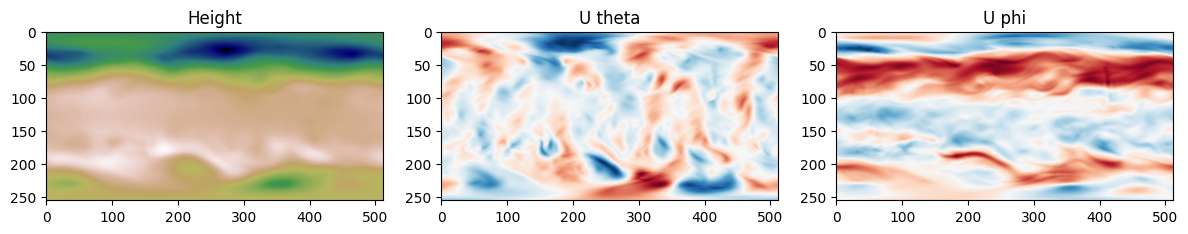

In [4]:
# Define a function to plot the state of the system at a given time step
def plot_state(u, cmap = "RdBu_r"):
    fig = plt.imshow(u.reshape(Lx, Ly), cmap = cmap)

plot_height = lambda u: plot_state(u, cmap = "gist_earth")
plot_velocity = lambda u: plot_state(u, cmap = "RdBu_r")

# Plot the state of the system at the first time step
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plot_height(H[0])
plt.title("Height")
plt.subplot(1, 3, 2)
plot_velocity(Utheta[0])
plt.title("U theta")
plt.subplot(1, 3, 3)        
plot_velocity(Uphi[0])
plt.title("U phi")
plt.tight_layout()
plt.show()

## SENSOR extraction

In [5]:
# EXTRACT SENSORS DATA

# We randomly select 10 sensors on the grid and extract their time series data from the height field H.
nsensors = 10
sensors_coordinates = np.vstack((np.random.choice(Lx, size = nsensors, replace = True), np.random.choice(Ly, size = nsensors, replace = True))).T
sensors_data = H.reshape(ntimes, Lx, Ly)[:,sensors_coordinates[:,0], sensors_coordinates[:,1]]
sensors_data = sensors_data.float()  # float copy so NaN can be written later
print("Sensors coordinates:\n", sensors_coordinates)
print("Sensors data shape:\t", sensors_data.shape)

H = np.vstack((H, H))
sensors_data = np.vstack((sensors_data, sensors_data))
ntimes = H.shape[0]

# ============================================================
# BROKEN SENSORS SIMULATION
# ============================================================
# `sensors_data` above is the PRISTINE (unbroken) sensor reading. The
# actual breakage is applied fresh, per RUN, inside run_full_pipeline()
# further down (see "## Esecuzione automatica dei 5 run"), so a single
# execution of the notebook launches all 5 configurations back to back
# without ever mutating this pristine copy.
#
#   1a -> ALL sensors broken, contiguous outage, length ~ U[50, 150]
#   1b -> ALL sensors broken, contiguous outage, length ~ U[250, 500]
#   2a -> ALL sensors broken, Bernoulli drops, p = 0.25
#   2b -> ALL sensors broken, Bernoulli drops, p = 0.50
#   3  -> ALL sensors broken with BOTH mechanisms at once
#         (contiguous outage 50-150 steps AND Bernoulli p=0.25 drops)

RUN_CONFIGS = {
    "1a": dict(mode="interval",  interval_range=(150, 250)),
    "1b": dict(mode="interval",  interval_range=(400, 800)),
    "2a": dict(mode="bernoulli", p=0.25),
    "2b": dict(mode="bernoulli", p=0.50),
    "3":  dict(mode="mix",       interval_range=(50, 150), p=0.25),
}


def apply_interval_break(sensors_data, sensor_idx, ntimes, interval_range, sensors_coordinates=None):
    """Mask ONE random contiguous block of time steps; block length ~ U[low, high]."""
    low, high = interval_range
    length = int(np.random.randint(low, high + 1))
    length = min(length, ntimes)
    t_start = int(np.random.randint(0, ntimes - length + 1))
    t_end = t_start + length - 1
    sensors_data[t_start:t_end + 1, sensor_idx] = float("nan")
    coord_str = f" (coord {sensors_coordinates[sensor_idx]})" if sensors_coordinates is not None else ""
    #print(f"[interval  low={low} high={high}] sensor {sensor_idx}{coord_str}: " f"steps {t_start}-{t_end} masked ({length} steps)")


def apply_bernoulli_break(sensors_data, sensor_idx, ntimes, p, sensors_coordinates=None):
    """Mask each time step of a sensor independently with probability p."""
    broken_mask = torch.rand(sensors_data[:, sensor_idx].shape) < p
    sensors_data[:, sensor_idx][broken_mask] = float("nan")
    coord_str = f" (coord {sensors_coordinates[sensor_idx]})" if sensors_coordinates is not None else ""
    #print(f"[bernoulli p={p}] sensor {sensor_idx}{coord_str}: "f"{broken_mask.sum().item()} of {ntimes} steps masked")


def break_sensors_for_run(sensors_data_raw, RUN, ntimes, sensors_coordinates=None):
    """Return a FRESH masked copy of sensors_data_raw for the given RUN label."""
    cfg = RUN_CONFIGS[RUN]
    sensors_data = sensors_data_raw.copy()
    nsensors_local = sensors_data.shape[1]
    #print(f"\n--- Applying RUN='{RUN}' sensor-breaking configuration: {cfg} ---\n")
    for local_idx in range(nsensors_local):
        if cfg["mode"] == "interval":
            apply_interval_break(sensors_data, local_idx, ntimes, cfg["interval_range"], sensors_coordinates)
        elif cfg["mode"] == "bernoulli":
            apply_bernoulli_break(sensors_data, local_idx, ntimes, cfg["p"], sensors_coordinates)
        elif cfg["mode"] == "mix":
            apply_interval_break(sensors_data, local_idx, ntimes, cfg["interval_range"], sensors_coordinates)
            apply_bernoulli_break(sensors_data, local_idx, ntimes, cfg["p"], sensors_coordinates)
        else:
            raise ValueError(f"Unknown mode: {cfg['mode']}")
    return sensors_data


Sensors coordinates:
 [[102 466]
 [179 214]
 [ 92 330]
 [ 14 458]
 [106  87]
 [ 71 372]
 [188  99]
 [ 20 359]
 [102 151]
 [121 130]]
Sensors data shape:	 torch.Size([1008, 10])


In [6]:
# PLOT DATA AVAILABILITY

def plot_data_availability(sensor_data, title_prefix, sensor_labels=None):
    """sensor_data: (ntimes, nsensors)"""
    availability = (~np.isnan(sensor_data))
    time          = np.arange(availability.shape[0])
    nsensors_plot = availability.shape[1]

    if sensor_labels is None:
        sensor_labels = np.arange(nsensors_plot)
    sensor_labels = np.asarray(sensor_labels)

    fig_height = max(3.0, 0.4 * nsensors_plot)
    _, ax = plt.subplots(1, 1, figsize=(10, fig_height))

    for sensor_idx in range(nsensors_plot):
        line = np.where(availability[:, sensor_idx] > 0.5, sensor_idx + 1.0, np.nan)
        ax.plot(time, line, linewidth=4, solid_capstyle="butt", label=f"S{sensor_labels[sensor_idx]}")

    ax.set_xlabel("Time step")
    ax.set_ylabel("Sensor")
    ax.set_yticks(np.arange(1, nsensors_plot + 1))
    ax.set_yticklabels([f"S{label}" for label in sensor_labels])
    ax.set_ylim(0.5, nsensors_plot + 0.5)
    ax.grid(True, axis="x", alpha=0.25)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Sensors")
    plt.title(title_prefix)
    plt.tight_layout()
    plt.show()

# NOTE: called once per RUN inside run_full_pipeline() (see
# "## Esecuzione automatica dei 5 run"), not at the top level here.


## Hyperparameters and helpers

In [7]:
# Keep PRISTINE copies of H and sensors_data. run_full_pipeline() derives a
# broken + reshaped/permuted (H, sensors_data) pair fresh for every RUN
# starting from these, so the 5 runs never compound on top of each other
# even when launched back-to-back in a single execution.

H_pristine = H.copy()
sensors_data_pristine = sensors_data.copy()

print("H_pristine shape:\t\t", H_pristine.shape)
print("sensors_data_pristine shape:\t", sensors_data_pristine.shape)

del Utheta, Uphi

H_pristine shape:		 (2016, 131072)
sensors_data_pristine shape:	 (2016, 10)


In [8]:
def plot_reconstruction(
    reconstruction,
    ground_truth,
    Lx,
    Ly,
    field_name="Surface elevation",
    field_unit=None,
    save_path=None,
    dpi=400,
    title_prefix=""
):
    """
    Plot reconstruction, ground truth, and absolute error.

    Parameters
    ----------
    reconstruction : np.ndarray
        Reconstructed field, flattened or already 2D.
    ground_truth : np.ndarray
        Ground-truth field, flattened or already 2D.
    Lx, Ly : int
        Spatial dimensions.
    field_name : str
        Name of the reconstructed field.
    field_unit : str, optional
        Physical unit, e.g. "m".
    save_path : str, optional
        Path where the figure will be saved.
    dpi : int
        Resolution for raster output.
    title_prefix : str
        Prefix for the figure title.
    """

    # Reshape if necessary
    reconstruction = np.asarray(reconstruction).reshape(Lx, Ly)
    ground_truth = np.asarray(ground_truth).reshape(Lx, Ly)

    # Absolute error
    absolute_error = np.abs(reconstruction - ground_truth)

    # Shared scale for reconstruction and ground truth
    vmin = min(reconstruction.min(), ground_truth.min())
    vmax = max(reconstruction.max(), ground_truth.max())

    # ---------------------------------------------------------
    # Figure
    # ---------------------------------------------------------
    fig, axes = plt.subplots(
        1, 3,
        figsize=(20, 4),
        constrained_layout=True
    )

    # Reconstruction
    im0 = axes[0].imshow(
        reconstruction,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        origin="lower",
        aspect="equal"
    )

    axes[0].set_title(
        f"{title_prefix}",
        fontsize=12,
        fontweight="bold"
    )

    # Ground truth
    im1 = axes[1].imshow(
        ground_truth,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        origin="lower",
        aspect="equal"
    )

    axes[1].set_title(
        "Ground truth",
        fontsize=12,
        fontweight="bold"
    )

    # Absolute error
    im2 = axes[2].imshow(
        absolute_error,
        cmap="magma",
        vmin=0,
        vmax=absolute_error.max(),
        origin="lower",
        aspect="equal"
    )

    axes[2].set_title(
        "Absolute error",
        fontsize=12,
        fontweight="bold"
    )

    # ---------------------------------------------------------
    # Clean axes
    # ---------------------------------------------------------
    for ax in axes:
        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(False)

    # ---------------------------------------------------------
    # Colorbars
    # ---------------------------------------------------------
    field_label = field_name
    if field_unit is not None:
        field_label += f" [{field_unit}]"

    cbar01 = fig.colorbar(
        im1,
        ax=axes[:2],
        fraction=0.025,
        pad=0.02
    )
    cbar01.set_label(field_label, fontsize=10)

    cbar2 = fig.colorbar(
        im2,
        ax=axes[2],
        fraction=0.046,
        pad=0.02
    )
    cbar2.set_label(
        f"Absolute error [{field_unit}]" if field_unit else "Absolute error",
        fontsize=10
    )

    plt.show()

In [9]:
# DataManager
LAGS = 100

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS = 100

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 5e-4    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training (T.1.*, T.2.*)
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 80           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 1               # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64]    # hidden sizes for decoder layers 
DROPOUT = 0.1                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)


## Complete pipeline (T.1.A - T.3.G)


In [10]:
def run_full_pipeline(RUN, H_pristine, sensors_data_pristine, sensors_coordinates,
                       ntimes, Lx, Ly, nsensors, device,
                       plot_availability=True, plot_reconstructions=False):
    """
    Run the FULL ablation pipeline (T.1.A -> T.3.G, 13 architectures) for a
    single sensor-breaking configuration `RUN`. Returns the resulting
    dataframe of test errors and also saves it to dataframe_errors_<RUN>.csv.
    """
    print("=" * 70)
    print(f"STARTING RUN '{RUN}'  ({RUN_CONFIGS[RUN]})")
    print("=" * 70 )

    # ------------------------------------------------------------
    # 1) Break sensors fresh, starting from the pristine (unbroken) data
    # ------------------------------------------------------------
    sensors_data = break_sensors_for_run(sensors_data_pristine, RUN, ntimes, sensors_coordinates)

    if plot_availability:
        plot_data_availability(sensors_data, f"Sensor data availability - RUN {RUN}",
                                sensor_labels=np.arange(nsensors))

    # ------------------------------------------------------------
    # 2) Duplicate/reshape/permute H and sensors_data together (as in the
    #    original SHRED-ROM setup), fresh from the pristine H every time.
    # ------------------------------------------------------------
    np.random.seed(42)  # reproducibility of the permutation only

    H_local = H_pristine.copy()
    sensors_data_local = sensors_data.copy()
    
    H_local = H_local.reshape(16, -1, Lx * Ly)
    sensors_data_local = sensors_data_local.reshape(16, -1, nsensors)

    permutation = np.random.permutation(sensors_data_local.shape[0])
    sensors_data_local = sensors_data_local[permutation]
    H_local = H_local[permutation]

    ERRORS = []

    def _save():
        df = pd.DataFrame(ERRORS)
        display(df)
        df.to_csv(f"dataframe_errors_{RUN}.csv", index=False)
        return df

    def _maybe_plot_reconstruction(manager, mshred, test_dataset, tag):
        if not plot_reconstructions:
            return
        engine = SHREDEngine(manager, mshred)
        test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
        plot_reconstruction(
            test_reconstruction["Surface elevation"][-1],
            H_local[-1][-1],
            Lx, Ly,
            field_name="Surface elevation",
            title_prefix=f"mSHRED_{tag.replace('.', '')}_{RUN}"
        )

    # ==============================================================
    # T.1.A / T.1.B / T.1.C: imputers (median / mean / last value)
    # ==============================================================
    for imputer, tag, label in [
        ("median",     "T.1.A", "median imputation for missing sensors"),
        ("mean",       "T.1.B", "mean imputation for missing sensors"),
        ("last_value", "T.1.C", "last-value imputation for missing sensors"),
    ]:
        print(f"--- [{RUN}] ({tag}): {label} ---")

        manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
        manager.add_data(H_local, id="Surface elevation", compress=COMPRESS,
                          measurements=sensors_data_local, imputer=imputer)
        train_dataset, val_dataset, test_dataset = manager.prepare()

        nn_input_shape = train_dataset[0][0].shape[1]
        nn_output_shape = train_dataset[0][1].shape[0]

        model_args = dict(
            encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
            dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
            decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
        )
        mshred = mSHRED(args=model_args).to(device)

        train_errors, valid_errors = fit(
            mshred, train_dataset, val_dataset,
            optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
            lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        )
        plot_training_curves(train_errors, valid_errors)

        test_error = evaluate_model(
            evaluate, mshred, train_dataset, val_dataset, test_dataset,
            model=f"(mSHRED): TR+{DECODER}", type=f"[{RUN}] ({tag}): {label}"
        )
        ERRORS.append(test_error)
        _save()
        _maybe_plot_reconstruction(manager, mshred, test_dataset, tag)

        del train_dataset, val_dataset, test_dataset

    # ==============================================================
    # T.2.A / T.2.B: GRUD / Attn-GRUD (share one dataset)
    # ==============================================================
    print(f"--- [{RUN}] (T.2): GRUD family ---")

    manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
    manager.add_data(H_local, id="Surface elevation", compress=COMPRESS,
                      measurements=sensors_data_local)
    train_dataset, val_dataset, test_dataset, X_mean = manager.prepare(masking_type="grud")

    nn_input_shape = train_dataset[0][0].shape[-1]
    nn_output_shape = train_dataset[0][1].shape[0]

    for encoder, model_label, tag, label in [
        ("grud",     "GRUD",      "T.2.A", "GRUD"),
        ("att_grud", "Attn-GRUD", "T.2.B", "Attn-GRUD"),
    ]:
        print(f"--- [{RUN}] ({tag}): {label} ---")

        model_args = dict(
            encoder=encoder, input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, X_mean=X_mean,
            decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
        )
        mshred = mSHRED(args=model_args).to(device)

        train_errors, valid_errors = fit(
            mshred, train_dataset, val_dataset,
            optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
            lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        )
        plot_training_curves(train_errors, valid_errors)

        test_error = evaluate_model(
            evaluate, mshred, train_dataset, val_dataset, test_dataset,
            model=f"(mSHRED): {model_label}+{DECODER}", type=f"[{RUN}] ({tag}): {label}"
        )
        ERRORS.append(test_error)
        _save()
        _maybe_plot_reconstruction(manager, mshred, test_dataset, tag)

    del train_dataset, val_dataset, test_dataset

    # ==============================================================
    # T.3.A..G: masking variants (share one dataset)
    # ==============================================================
    print(f"--- [{RUN}] (T.3): masking family ---")

    NUM_EPOCHS_MASK = 250  # only the masking family trains for 250 epochs, as in the original notebook

    manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
    manager.add_data(H_local, id="Surface elevation", compress=COMPRESS, measurements=sensors_data_local)
    train_dataset, val_dataset, test_dataset = manager.prepare(masking_type=MASKING_TYPE)

    nn_input_shape = train_dataset.X.shape[-1]
    nn_output_shape = train_dataset.Y.shape[-1]

    masking_configs = [
        ("transformer",              False, "T.3.A", "masking"),
        ("transformer",              True,  "T.3.B", "masking x2 channels"),
        ("transformer_hidden_mask",  None,  "T.3.C", "masking hidden space"),
        ("transformer_attn_mask",    False, "T.3.D", "masking MHSA"),
        ("transformer_attn_mask",    True,  "T.3.E", "masking x2 channels + MHSA"),
        ("transformer_learned_mask", None,  "T.3.F", "masking MHSA learned"),
        ("transformer_learned_mask", True,  "T.3.G", "masking x2 channels + MHSA learned"),
    ]

    for encoder, double_channels, tag, label in masking_configs:
        print(f"--- [{RUN}] ({tag}): {label} ---")

        model_args = dict(
            encoder=encoder, encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
            dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
            decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
        )
        if double_channels is not None:
            model_args["double_channels"] = double_channels

        mshred = mSHRED(args=model_args).to(device)

        train_errors, valid_errors = fit(
            mshred, train_dataset, val_dataset,
            optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS_MASK, patience=PATIENCE, verbose=VERBOSE_TRAIN,
            lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
            masking_type=MASKING_TYPE,
        )
        plot_training_curves(train_errors, valid_errors)

        test_error = evaluate_model(
            evaluate, mshred, train_dataset, val_dataset, test_dataset,
            model=f"(mSHRED): TR+{DECODER}", type=f"[{RUN}] ({tag}): {label}", masking_type=MASKING_TYPE
        )
        ERRORS.append(test_error)
        _save()
        _maybe_plot_reconstruction(manager, mshred, test_dataset, tag)

    del train_dataset, val_dataset, test_dataset

    dataframe_errors = pd.DataFrame(ERRORS)
    print(f"\n--- RUN '{RUN}' complete: {len(ERRORS)} architectures evaluated ---")
    display(dataframe_errors)

    return dataframe_errors


## Automatic run

| RUN | Sensor failures                                                                              |
| --- | -------------------------------------------------------------------------------------------- |
| 1a  | All sensors, contiguous outage, duration ~ U[50, 150]                                        |
| 1b  | All sensors, contiguous outage, duration ~ U[250, 500]                                       |
| 2a  | All sensors, Bernoulli drop, p = 0.25                                                        |
| 2b  | All sensors, Bernoulli drop, p = 0.50                                                        |
| 3   | All sensors, both failures occurring simultaneously (outage 50-150 steps + Bernoulli p=0.25) |



STARTING RUN '1a'  ({'mode': 'interval', 'interval_range': (150, 250)})


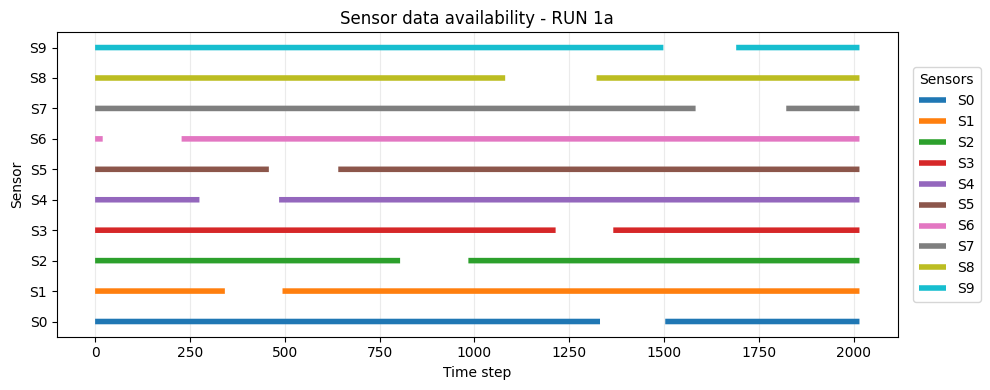

--- [1a] (T.1.A): median imputation for missing sensors ---

Data shapes after preparation:
Train:	 torch.Size([1512, 100, 10]) -> torch.Size([1512, 100])
Val:	 torch.Size([252, 100, 10]) -> torch.Size([252, 100])
Test:	 torch.Size([252, 100, 10]) -> torch.Size([252, 100])
Starting training...


Training: 100%|██████████| 200/200 [03:34<00:00,  1.07s/it, Train Loss=0.02170, Val Loss=0.02898, Patience=0, Best Val Loss=0.02898, LR=0.00e+00]

Training completed with best validation loss: 0.0290


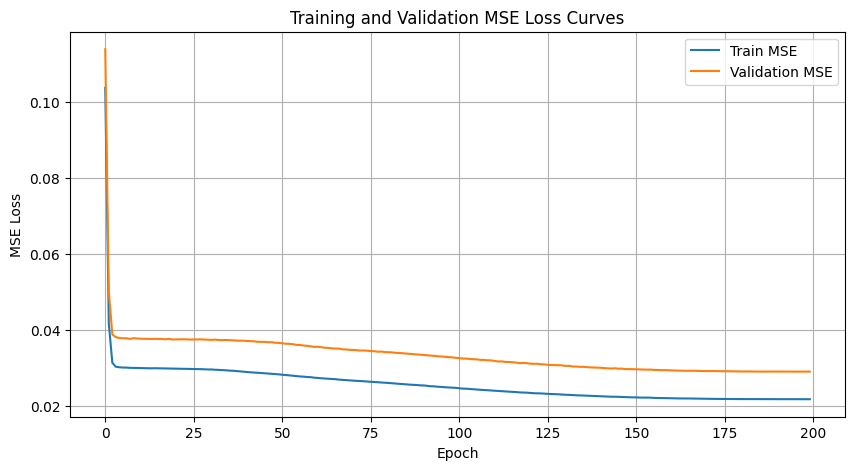

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre,train-nrmse,val-nrmse,test-nrmse
0,(mSHRED): TR+cnn,[1a] (T.1.A): median imputation for missing se...,0.021697,0.028975,0.02904,0.294846,0.335746,0.336143,0.148966,0.167806,0.168122


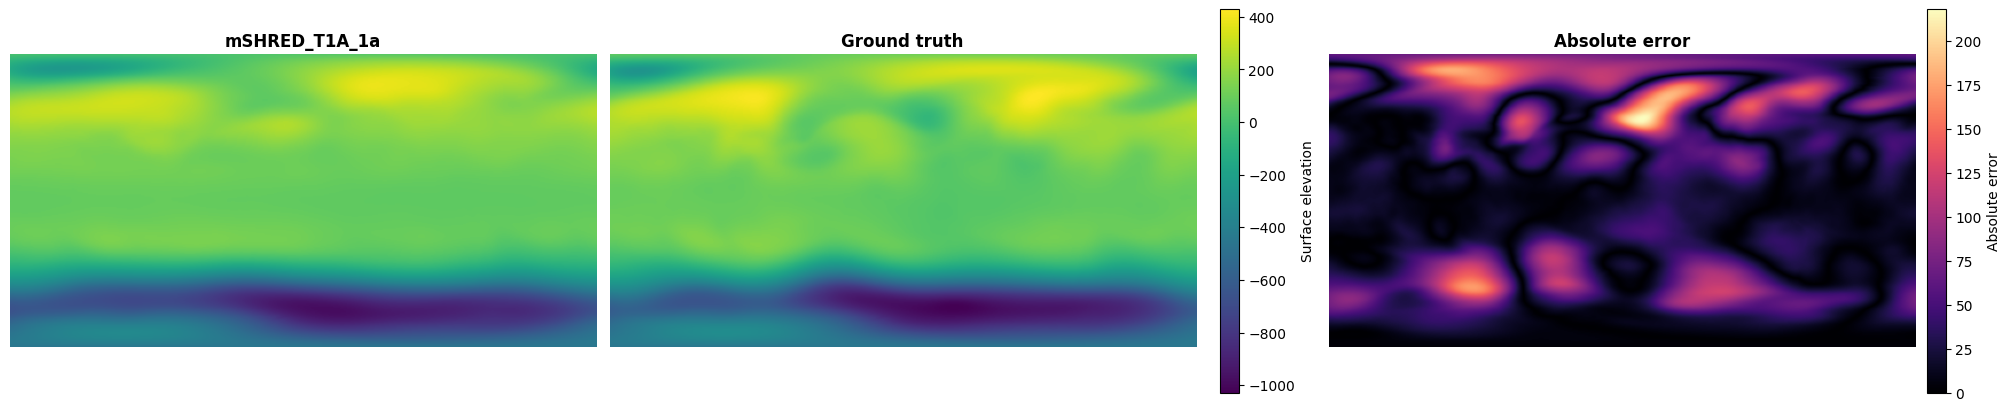

--- [1a] (T.1.B): mean imputation for missing sensors ---

Data shapes after preparation:
Train:	 torch.Size([1512, 100, 10]) -> torch.Size([1512, 100])
Val:	 torch.Size([252, 100, 10]) -> torch.Size([252, 100])
Test:	 torch.Size([252, 100, 10]) -> torch.Size([252, 100])
Starting training...


Training:  42%|████▏     | 83/200 [01:44<03:00,  1.54s/it, Train Loss=0.02515, Val Loss=0.03376, Patience=0, Best Val Loss=0.03380, LR=3.16e-04]

In [ ]:
ALL_RUNS = ["1a", "1b", "2a", "2b", "3"]

# Set to False to keep the output of a single "Run All" lighter (every
# architecture is still trained and evaluated for every RUN regardless).
PLOT_AVAILABILITY = True
PLOT_RECONSTRUCTIONS = True

all_run_dataframes = {}

for RUN in ALL_RUNS:
    all_run_dataframes[RUN] = run_full_pipeline(
        RUN, H_pristine, sensors_data_pristine, sensors_coordinates,
        ntimes, Lx, Ly, nsensors, device,
        plot_availability=PLOT_AVAILABILITY,
        plot_reconstructions=PLOT_RECONSTRUCTIONS,
    )

print("\nAll runs completed:", list(all_run_dataframes.keys()))
